# JavaScript: Creating and Using Decorators

This course covers the JavaScript decorator proposal — what decorators are, how to implement method, class, property, accessor, and auto-accessor decorators, how to compose them into reusable libraries, and how to build a decorator-based web framework with dependency injection and metadata-driven validation.

## Table of Contents

- [Module 01: Introduction to Decorators](#module-01-introduction-to-decorators)
- [Module 02: Implementing a Decorators Library](#module-02-implementing-a-decorators-library)
- [Module 03: Implementing a Decorator-Based Web Framework](#module-03-implementing-a-decorator-based-web-framework)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Introduction to Decorators

An introduction to the JavaScript decorator proposal — what decorators are, their types, the metaprogramming concept behind them, and how to implement your first method decorator using Babel.js.

### What Are Decorators?

A **decorator** is a function executed at runtime that modifies a class or one of its members. Decorators use the `@name` syntax placed immediately before the class element they decorate.

```javascript
class WeatherAPI {
  @cached({ timeToLive: 1000 })
  getForecast(city) {
    return { ... }
  }
}

function cached(cachingConfig) {
  // returns a decorator function
}
```

#### Types of Decorators

| Type | Target |
|---|---|
| **Method** | A class method |
| **Class** | The class itself |
| **Accessor** | A getter or setter |
| **Property** | A class field |
| **Auto-accessor** | An `accessor`-declared field |

### Metaprogramming

> Metaprogramming is a programming technique in which computer programs have the ability to treat other programs as their data. It means that a program can be designed to read, generate, analyze or transform other programs, and even modify itself while running.

Decorators are a form of metaprogramming — they let you write code that modifies other code at runtime.

### Decorators in TypeScript Frameworks

Decorators have been available in TypeScript for years and are heavily used in popular frameworks like **Nest.js** (web framework) and **TypeORM** (ORM):

```typescript
// Nest.js — routing with decorators
@Controller('weather')
export class WeatherAPI {
  @Inject('FORECAST_CLIENT')
  private readonly forecastClient: ForecastClient

  @Get(':cityName')
  async weatherForecast(@Param() params): Promise<Forecast> {
    return this.forecastClient.getForecast(params.cityName);
  }
}
```

```typescript
// TypeORM — schema definition with decorators
@Entity()
export class User {
  @PrimaryGeneratedColumn()
  id: number

  @Column()
  name: string

  @Column()
  isAdmin: boolean
}
```

The JavaScript standard for decorators is recent (TC39 Stage 3 as of course creation). TypeScript 5 implements the same proposal, so TypeScript examples translate directly to JavaScript.

### Important Prerequisites

Because decorators involve writing many functions that manipulate other functions, three foundational JavaScript concepts are essential:

#### Higher-order Functions

A function that takes another function as a parameter:

```javascript
function process(numbers, func) {
  const result = []
  for (let i = 0; i < numbers.length; i++) {
    const processed = func(numbers[i])
    result.push(processed)
  }
  return result
}

const arr = [1, 2, 3]
const result = process(arr, (n) => n * 2)
console.log(result) // [2, 4, 6]
```

#### Currying

Creating a specialised function from a more general one:

```javascript
function add(left) {
  return function (right) {
    return left + right
  }
}

const add5 = add(5)   // add5 is itself a function
console.log(add5(20)) // 25
console.log(add5(30)) // 35
```

#### Closure

The inner function in the example above works because it has access to its surrounding scope — it *closes over* `left`. This is how decorator factories capture configuration: the outer function's parameters remain accessible inside the returned decorator.

### Method Decorators

A method decorator is a function that receives the original method and a context object, and returns a new function that replaces it.

```javascript
function myDecorator(target, context) {
  return function (...args) {
    return 'Hello world!'
  }
}

class GitHubClient {
  @myDecorator
  async getRepos() {
    console.log('Getting GitHub repos...')
  }
}

console.log(new GitHubClient().getRepos()) // Hello world!
```

`target` is the original method. `context` provides metadata about the decorated element.

#### Decorator Context Object (TypeScript type for reference)

```typescript
type ClassMethodDecorator = (
  target: Function,
  context: {
    kind: 'method'
    name: string | symbol
    static: boolean
    private: boolean
    access: { get: () => unknown }
    addInitializer(initializer: () => void): void
    metadata: Record<PropertyKey, unknown>
  },
) => Function | void
```

Key fields:
- **`kind`** — `'method'` for method decorators
- **`name`** — the method name (useful for logging)
- **`addInitializer`** — registers a callback to run after the class is fully defined
- **`metadata`** — shared object for storing decorator-level data on the class

#### Logging Decorator Example

```javascript
// Logs timestamps before and after each method call
function log(target, context) {
  return function (...args) {
    console.log(`Calling method ${context.name} at ${new Date().toISOString()}`)
    const result = target.apply(this, args)
    console.log(`Method finished ${context.name} at ${new Date().toISOString()}`)
    return result
  }
}

class GitHubClient {
  @log
  getRepos() {
    console.log('Getting GitHub repos...')
  }
}

new GitHubClient().getRepos()
// > Calling method getRepos at 2023-09-10T16:54:09.693Z
// > Getting GitHub repos...
// > Method finished getRepos at 2023-09-10T16:54:09.793Z
```

`target.apply(this, args)` forwards the original `this` context and all arguments to the original method. Always use this pattern, not a plain `target(...args)` call, to avoid losing instance context.

#### Common Applications of Method Decorators

- **Logging** — record method entry/exit
- **Metrics/Tracing** — measure execution time
- **Caching** — cache return values
- **Transactions** — wrap in a DB transaction
- **Callbacks** — register event handlers

#### Limitations

- **Regular functions** — decorators only work on class methods (a proposal to support regular function decorators exists but is not yet standardised)
- **Constructors** — cannot directly decorate a constructor; class decorators provide a workaround (covered in Module 03)

### State of Decorators in JavaScript

- Going through the TC39 standardisation process — at **Stage 3** (changes unlikely)
- Already implemented by **TypeScript 5**
- Not yet natively supported by JavaScript engines — enabled via **Babel.js**

### Babel.js

Babel.js is a JavaScript compiler that transforms modern JavaScript (including decorator syntax) into code executable by current JavaScript engines.

**Install:**
```bash
npm install --save-dev @babel/core
npm install --save-dev @babel/preset-env
npm install --save-dev @babel/plugin-proposal-decorators
```

**`babel.config.json`:**
```json
{
  "presets": ["@babel/preset-env"],
  "plugins": [
    ["@babel/plugin-proposal-decorators", { "version": "2023-11" }]
  ]
}
```

**Compile and run:**
```bash
babel src -d lib   # compile src/ → lib/
node lib/app.js
```


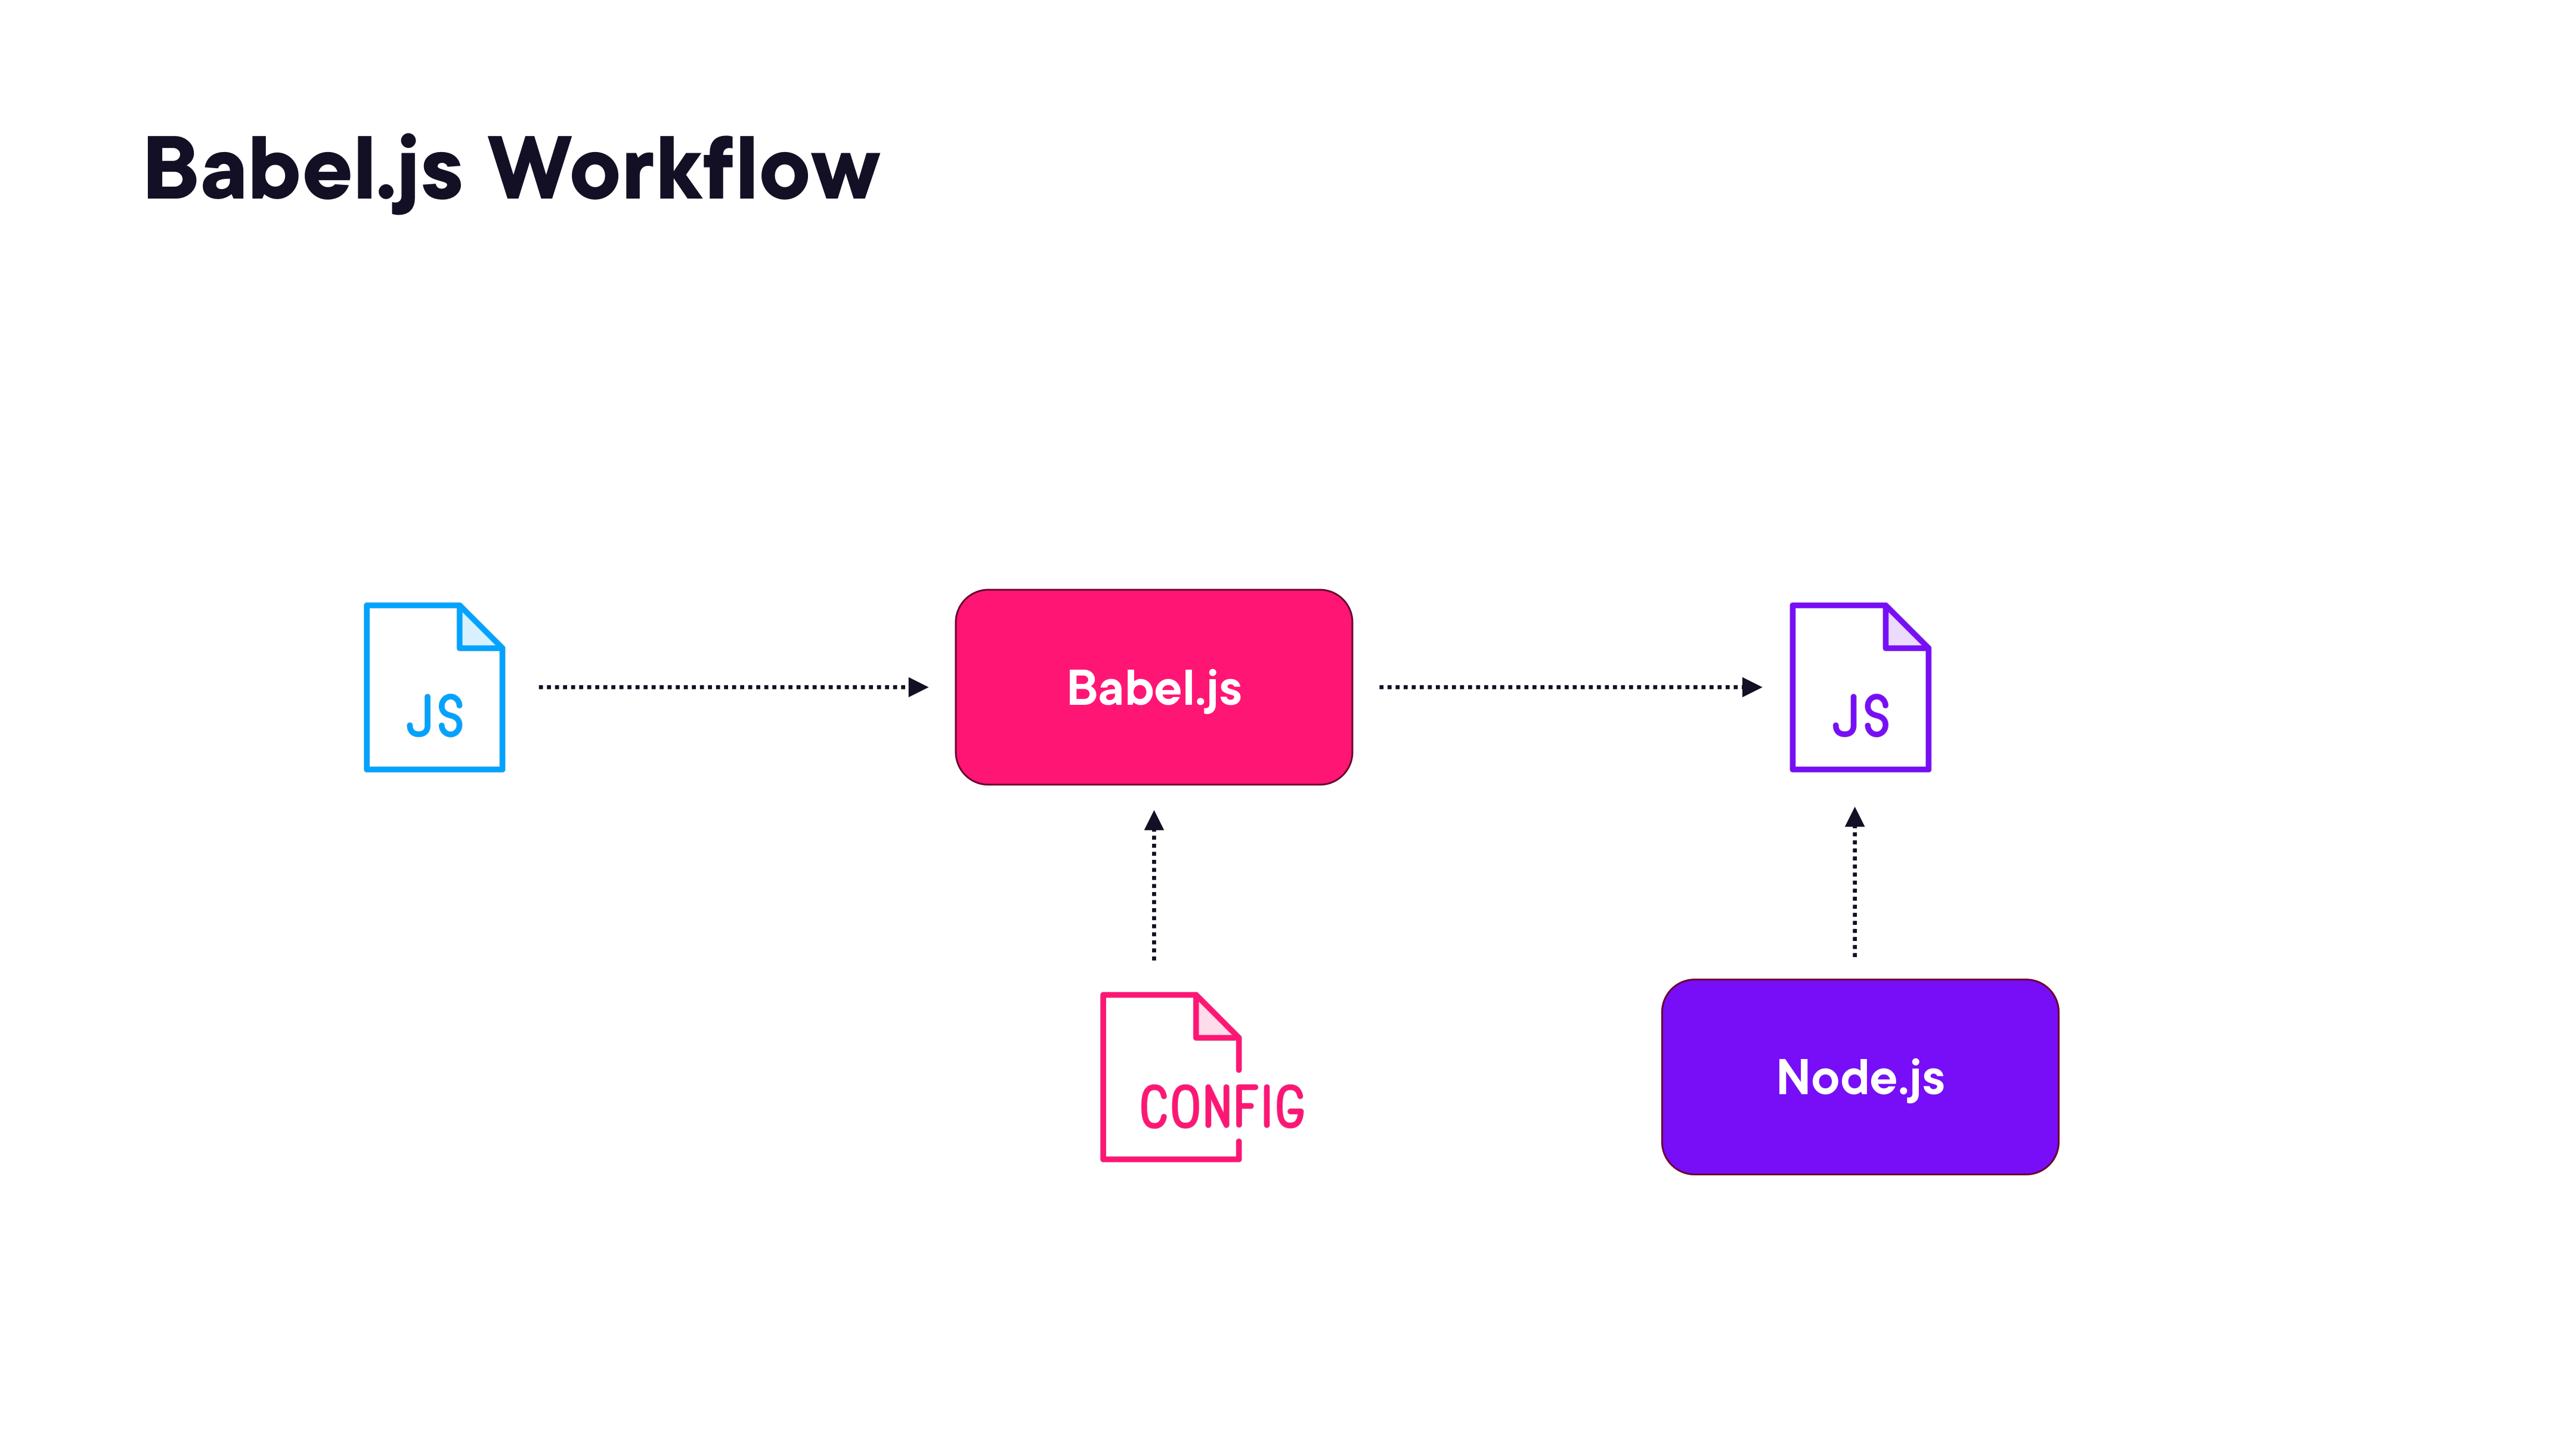

In [2]:
render_diagram(Path("assets/01-babel-workflow.png"))

### Demo: Introduction to Decorators

This demo sets up a Babel-configured Node.js project and implements a `@retry` decorator that automatically retries a failed async method — improving reliability without cluttering business logic.

See [`01-introduction-to-decorators-demos/`](01-introduction-to-decorators-demos/) for the full project.

The entry point (`src/app.js`) shows a `WeatherAPI` class whose `getWeather` method randomly throws to simulate network failures. The project is configured with `babel.config.json` to transpile decorator syntax via `@babel/plugin-proposal-decorators`.

---

## Module 02: Implementing a Decorators Library

Covers decorator factories for configurable decorators, applying multiple decorators to a single method, understanding execution order, and three patterns for structuring a decorators library: standalone functions, class methods, and factory functions.

### Decorator Factories

A basic decorator has a fixed behaviour. A **decorator factory** is a function that *returns* a decorator, allowing callers to pass configuration:

```javascript
// Plain decorator — no configuration
function log(target, context) {
  const resultMethod = async function (...args) {
    logger.log(`Running method ${context.name}`, Logger.INFO)
    const res = target.apply(this, args)
    logger.log(`Finished method ${context.name}`, Logger.INFO)
    return res
  }
  return resultMethod
}

// Decorator factory — log level is configurable
function log(logLevel) {
  return function (target, context) {
    const resultMethod = async function (...args) {
      logger.log(`Running method ${context.name}`, logLevel)
      const res = target.apply(this, args)
      logger.log(`Finished method ${context.name}`, logLevel)
      return res
    }
    return resultMethod
  }
}

class GitHubClient {
  @log(Logger.INFO)   // factory called with config, returns decorator
  getRepoInfo(repo) { ... }
}
```

**Key rule:** a decorator factory must be *called* at the decorator site (e.g. `@log(Logger.INFO)`). You cannot use `@log()` with a plain decorator, and you cannot use `@log` (without parentheses) with a factory — the two forms are not interchangeable.

### Multiple Decorators

Multiple decorators can be stacked on a single method. They apply from **bottom to top** (innermost first):

```javascript
class GitHubClient {
  @time('get-report-info.duration')
  @retry(1000, 3)
  getRepoInfo(repo) { ... }
}
```

The decorator order affects which wraps which. `@time` above `@retry` means `@time` measures the *total* duration including all retry attempts; swapping them would make `@time` measure individual call attempts.


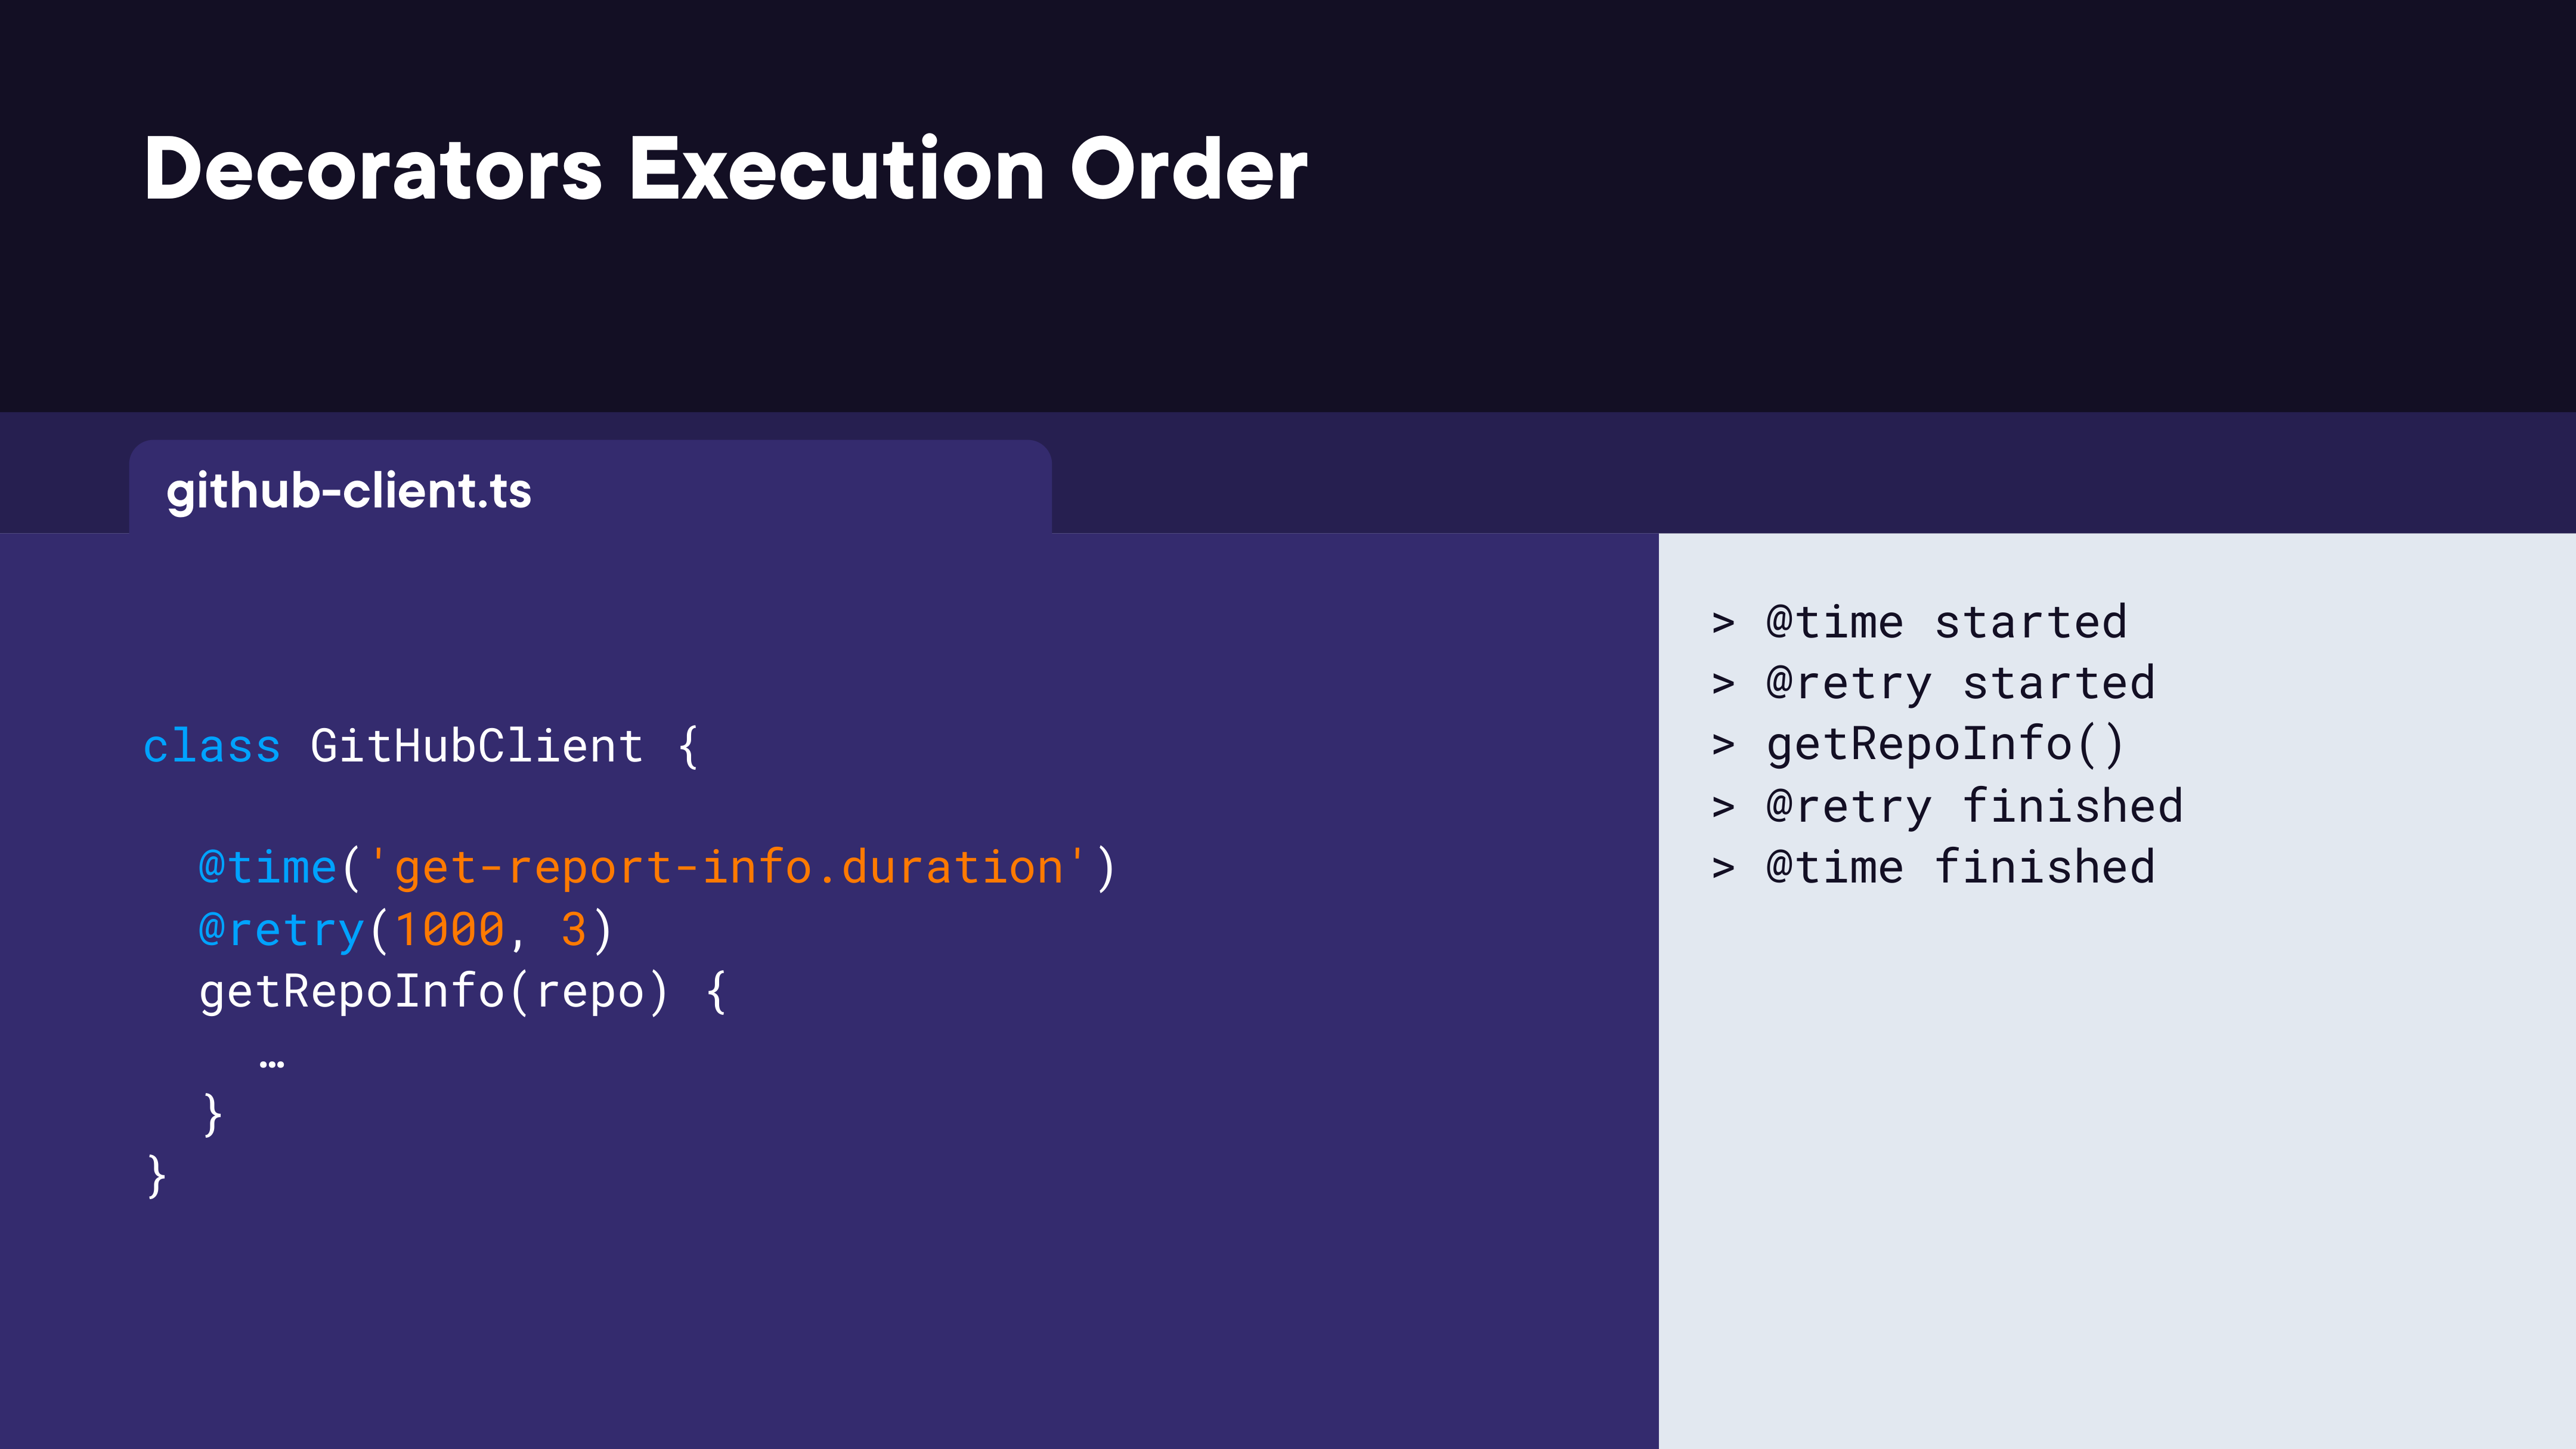

In [3]:
render_diagram(Path("assets/03-decorator-execution-order.png"))


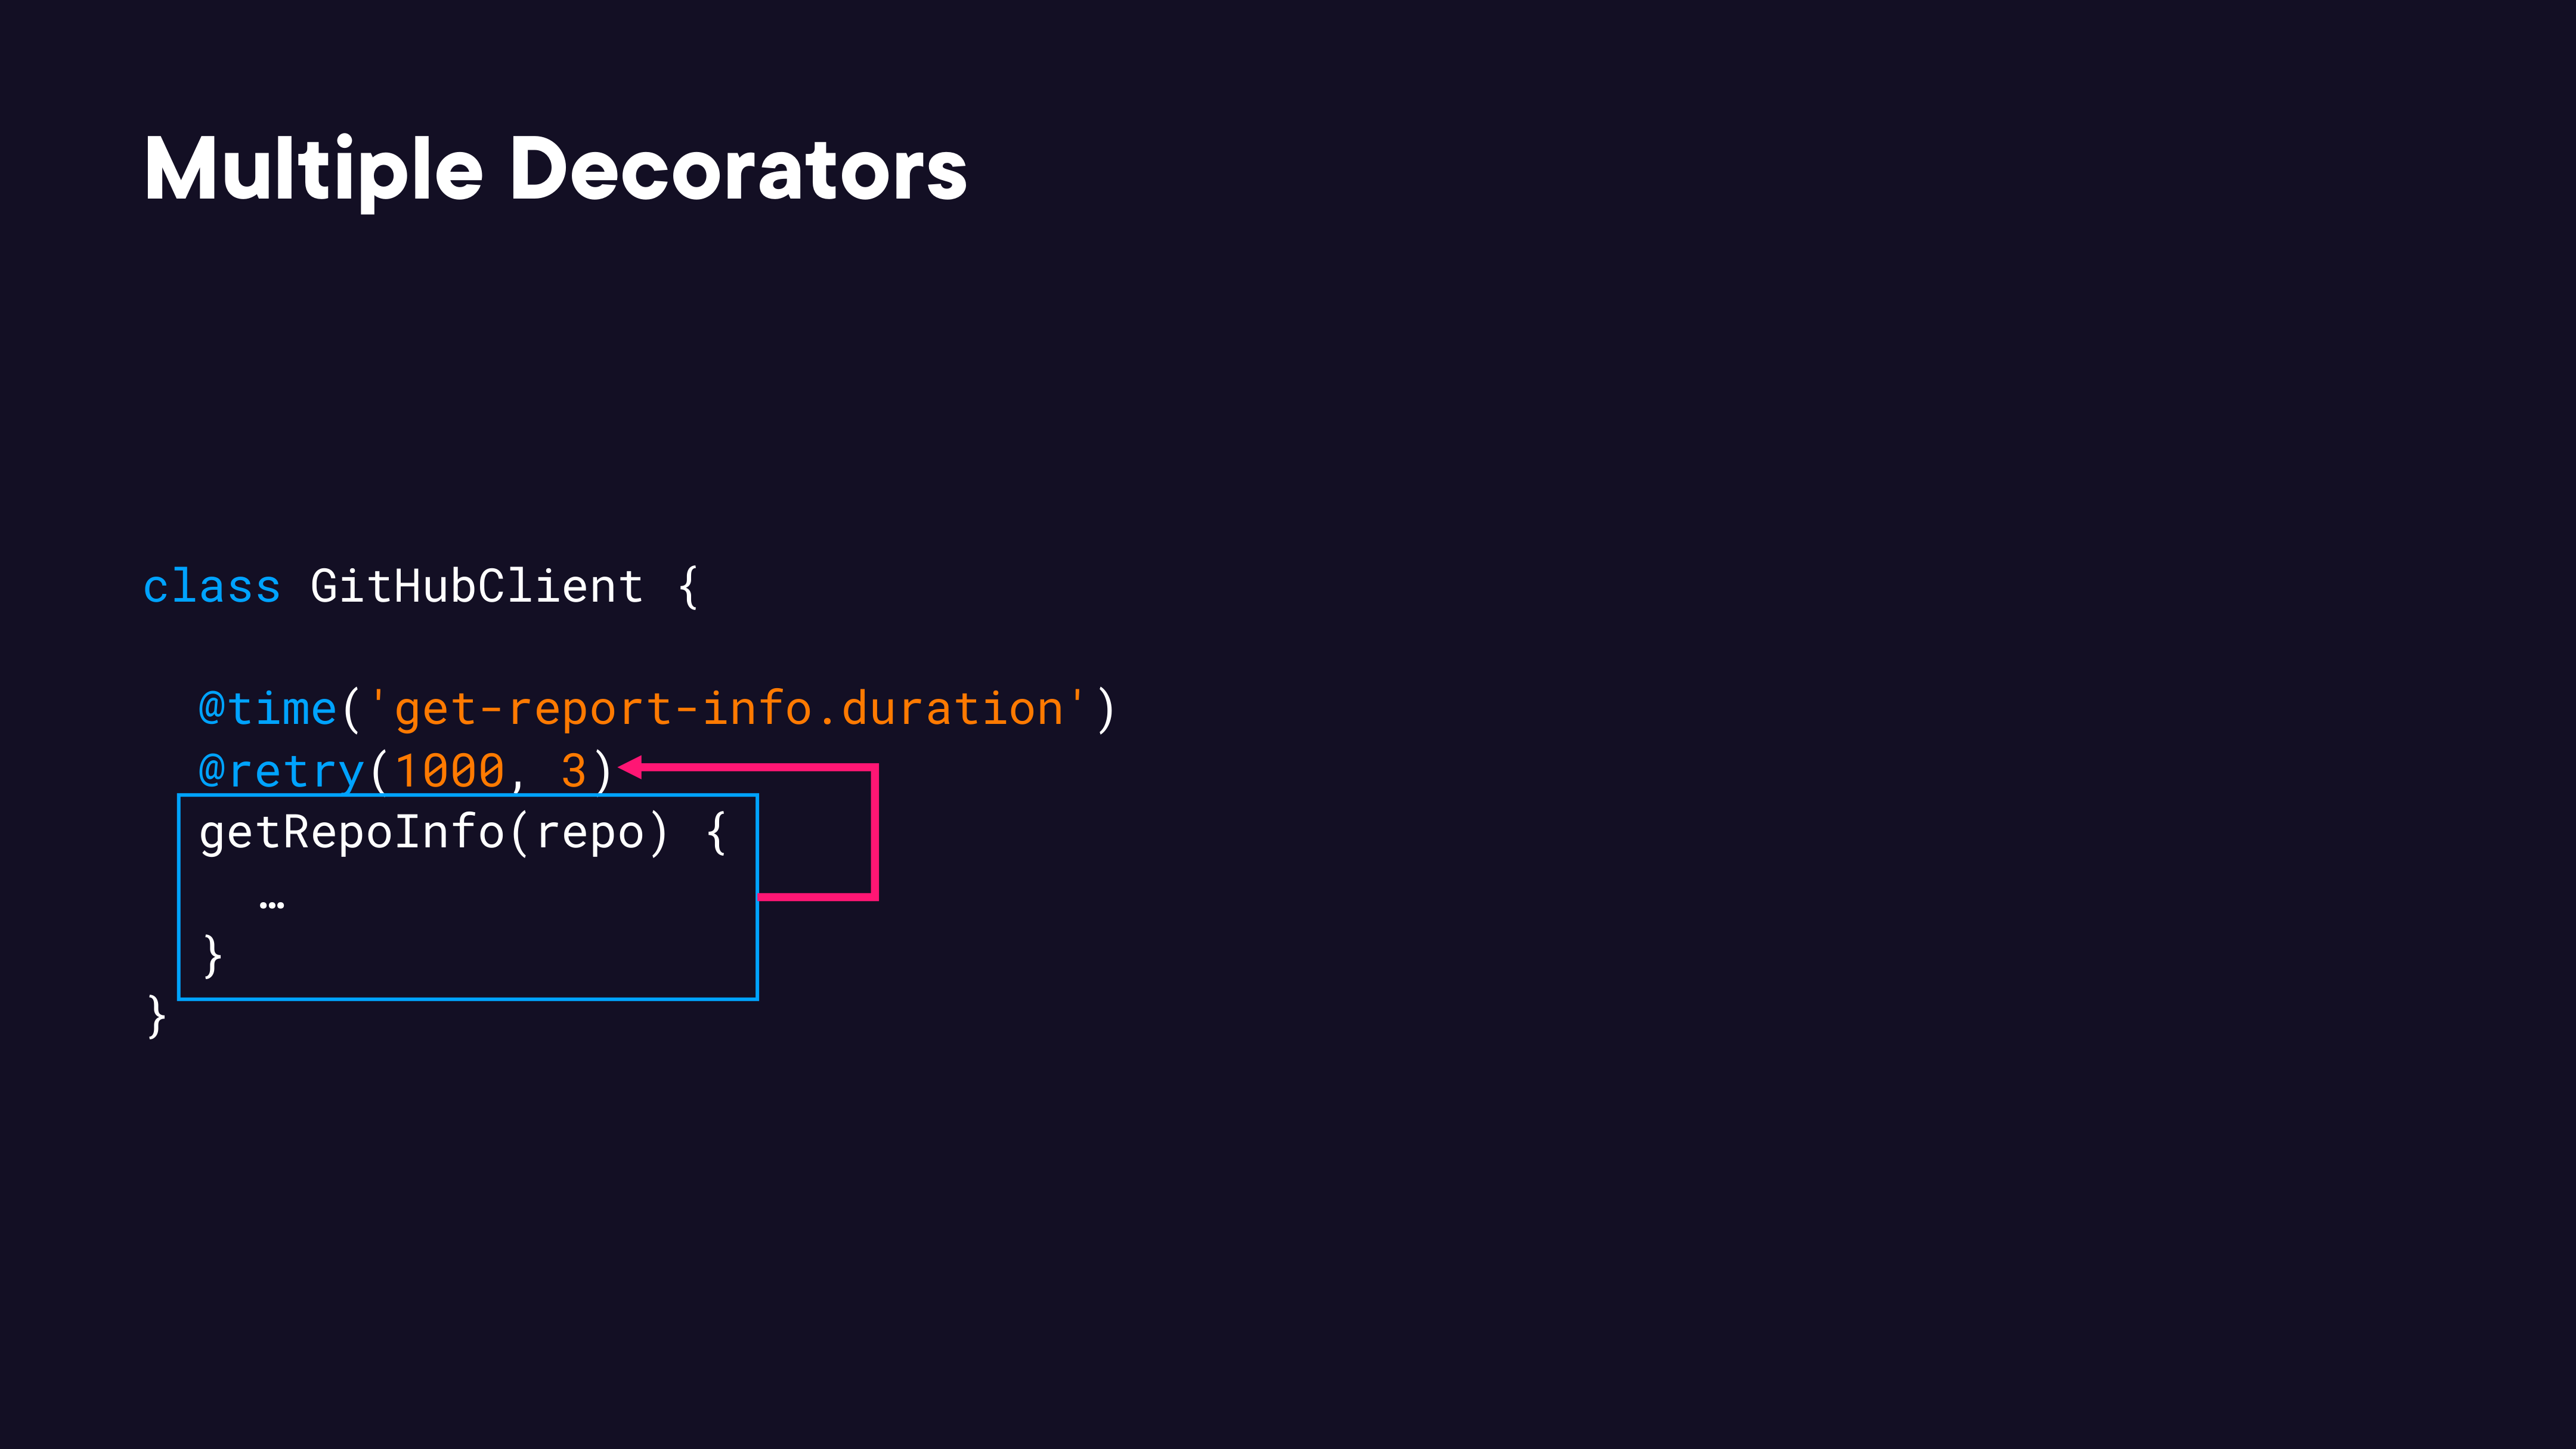

In [4]:
render_diagram(Path("assets/02-multiple-decorators-annotation.png"))


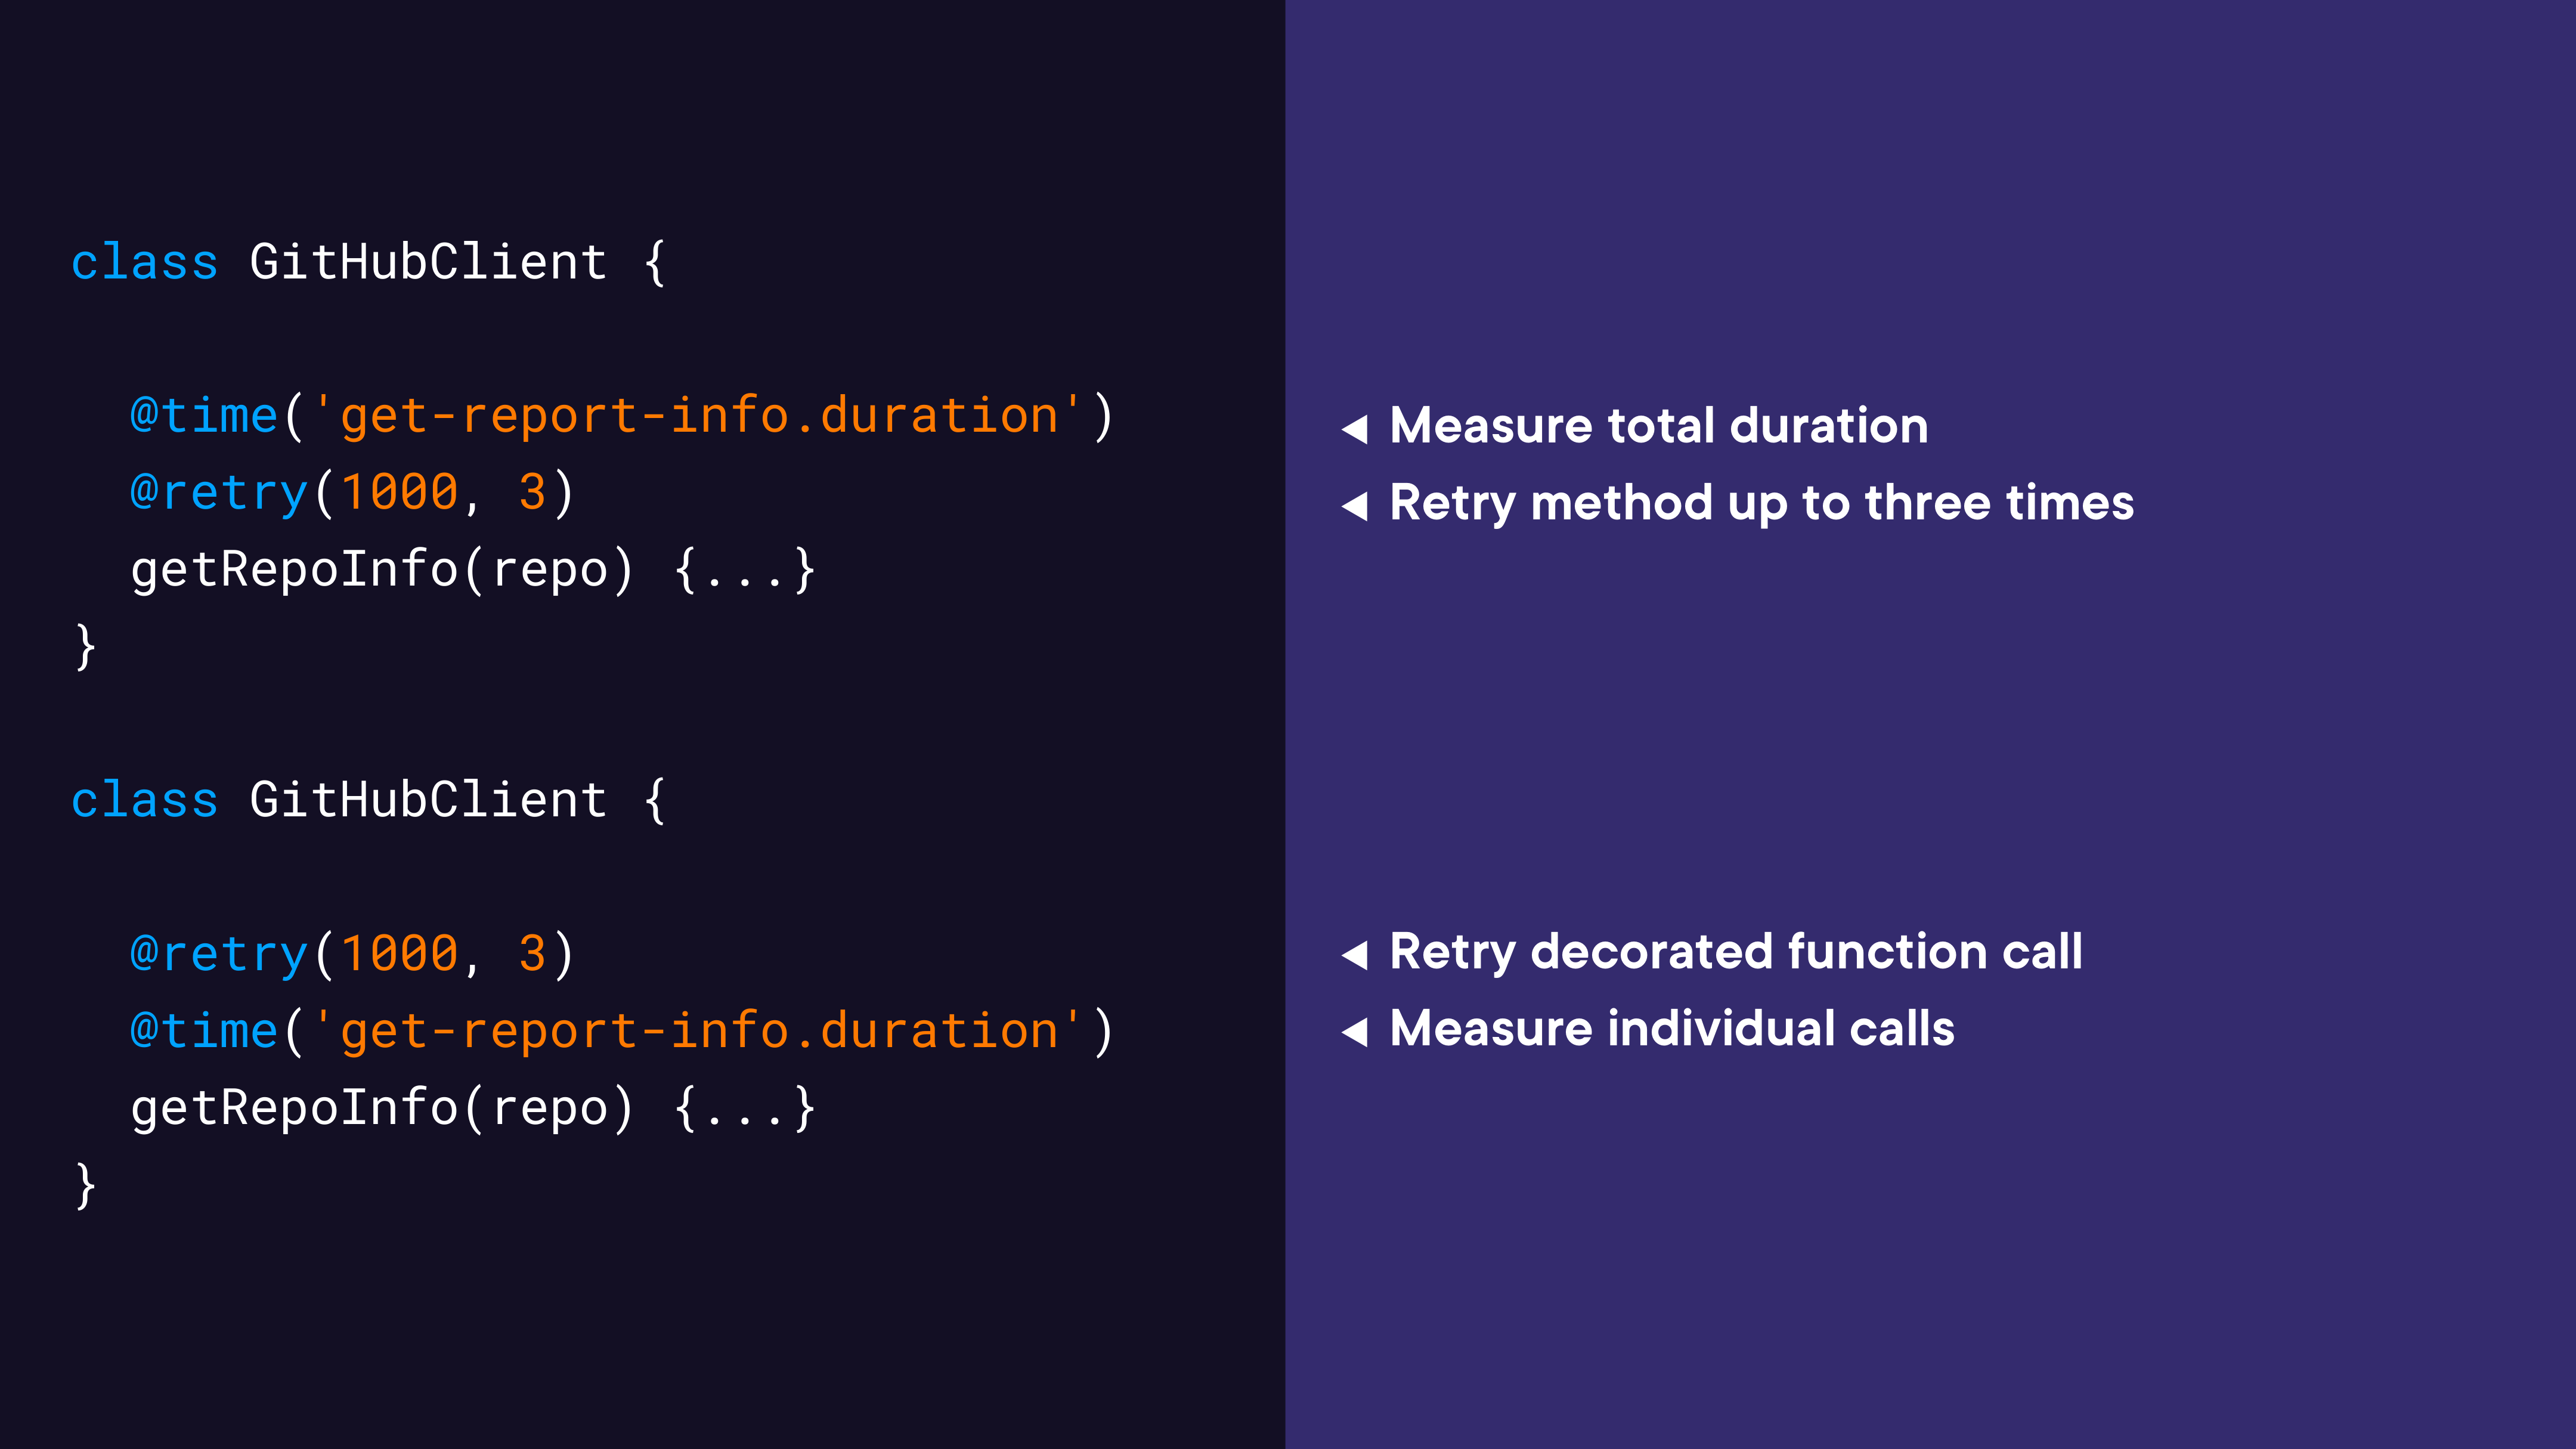

In [5]:
render_diagram(Path("assets/04-decorator-order-comparison.png"))

### Decorator Patterns

Three patterns for structuring a reusable decorators library:

#### 1. Class Method as a Decorator

Bind decorators to a class so they can share state via instance fields:

```javascript
class Retrier {
  constructor(delayMs, maxAttempts) {
    this.delayMs = delayMs
    this.maxAttempts = maxAttempts
  }

  retry() {
    return function (target, context) {
      const resultMethod = async function (...args) {
        // uses this.delayMs and this.maxAttempts from the Retrier instance
      }
      return resultMethod
    }
  }
}

const retrier = new Retrier(1000, 3)

class GitHubClient {
  @retrier.retry()
  getRepoInfo(repo) { ... }
}
```

#### 2. Decorators Composition

Combine multiple decorators into a named composite decorator to reduce boilerplate at the call site:

```javascript
function safeCaching(target, context) {
  const withRetry = retry(target, context)
  const withCache = cache(withRetry, context)
  const withTime  = time(withCache, context)
  return withTime
}

class WeatherAPI {
  @safeCaching
  getWeatherForecast() { ... }
}
```

When decorators are factories, pass the factory result before calling the next decorator:

```javascript
function safeRetry(target, context) {
  const retryDecorator = retry({ maxRetryAttempts: 4, delayMs: 500 })
  const withRetry = retryDecorator(target, context)
  const withCache = cache(withRetry, context)
  const withTime  = time(withCache, context)
  return withTime
}
```

#### 3. Collecting Data in Decorators

When multiple decorated methods need to share a data structure (e.g. collected metrics), there are three approaches:

**Separate module-level variable:**
```javascript
const metricsMap = new Map()
function time(metricName) {
  metricsMap.set(metricName, [])
  return function (target, context) { ... }
}
```

**Class instance:**
```javascript
class Metrics {
  metricsMap = new Map()
  time(metricName) {
    this.metricsMap.set(metricName, [])
    return function (target, context) { ... }
  }
}
```

**Factory function (recommended — avoids global state):**
```javascript
function metricsFactory() {
  const metricValues = new Map()
  function time(metricName) {
    metricValues.set(metricName, [])
    return function (target, context) { ... }
  }
  return { metricValues, time }
}

const { metricValues, time } = metricsFactory()
```

### Demo: Implementing a Decorators Library

This demo builds on the `@retry` decorator from Module 01 by converting it to a decorator factory with configurable `maxRetryAttempts` and `delayMs` parameters. It adds a `@log` decorator, a `Metric` class method decorator for timing, and demonstrates combining them via decorator composition (`logAndRetry`).

See [`02-implementing-decorators-library-demos/`](02-implementing-decorators-library-demos/) for the full project.

Key patterns in `src/app.js`:

```javascript
// Decorator factory with configurable retry options
function retry(retryOptions) {
  return function(target, context) {
    const resultMethod = async function (...args) {
      for (let attemptNum = 1; attemptNum <= retryOptions.maxRetryAttempts; attemptNum++) {
        try {
          return await target.apply(this, args)
        } catch (error) {
          if (attemptNum < retryOptions.maxRetryAttempts) {
            await sleep(retryOptions.delayMs)
          }
        }
      }
    }
    return resultMethod
  }
}

// Composition: apply retry then log via a single composite decorator
function logAndRetry(target, context) {
  const retryDecorator = retry({ maxRetryAttempts: 4, delayMs: 500 })
  const targetWithRetries = retryDecorator(target, context)
  return log(targetWithRetries, context)
}

class WeatherAPI {
  @logAndRetry
  @weatherTiming.time()
  async getWeather(city) { ... }
}
```

---

## Module 03: Implementing a Decorator-Based Web Framework

Covers all remaining decorator types (class, property, accessor, auto-accessor), builds a minimal web framework with `@Controller`/`@Get` routing on top of Express.js, implements dependency injection via `@Injectable`/`@Inject`, uses decorator metadata for a validation library, and surveys current limitations and future proposals.

### What We Will Build

A minimal decorator-based web framework loosely inspired by Nest.js with two features:

| Feature | Description |
|---|---|
| **Web framework** | Handle HTTP requests via `@Controller` and `@Get`/`@Post` decorators |
| **Dependency injection** | Automatically create and wire an object graph via `@Injectable` and `@Inject` |

Target API:

```javascript
@Controller('/api')
class WeatherController {
  @Get('/weather')
  public get() {
    return { apiVersion: 'v1', temperature: 20, humidity: 80, city: 'London' }
  }
}

startApp()
```

```bash
wget weather.io/api/weather
# { "apiVersion": "v1", "temperature": 20, "humidity": 80, "city": "London" }
```


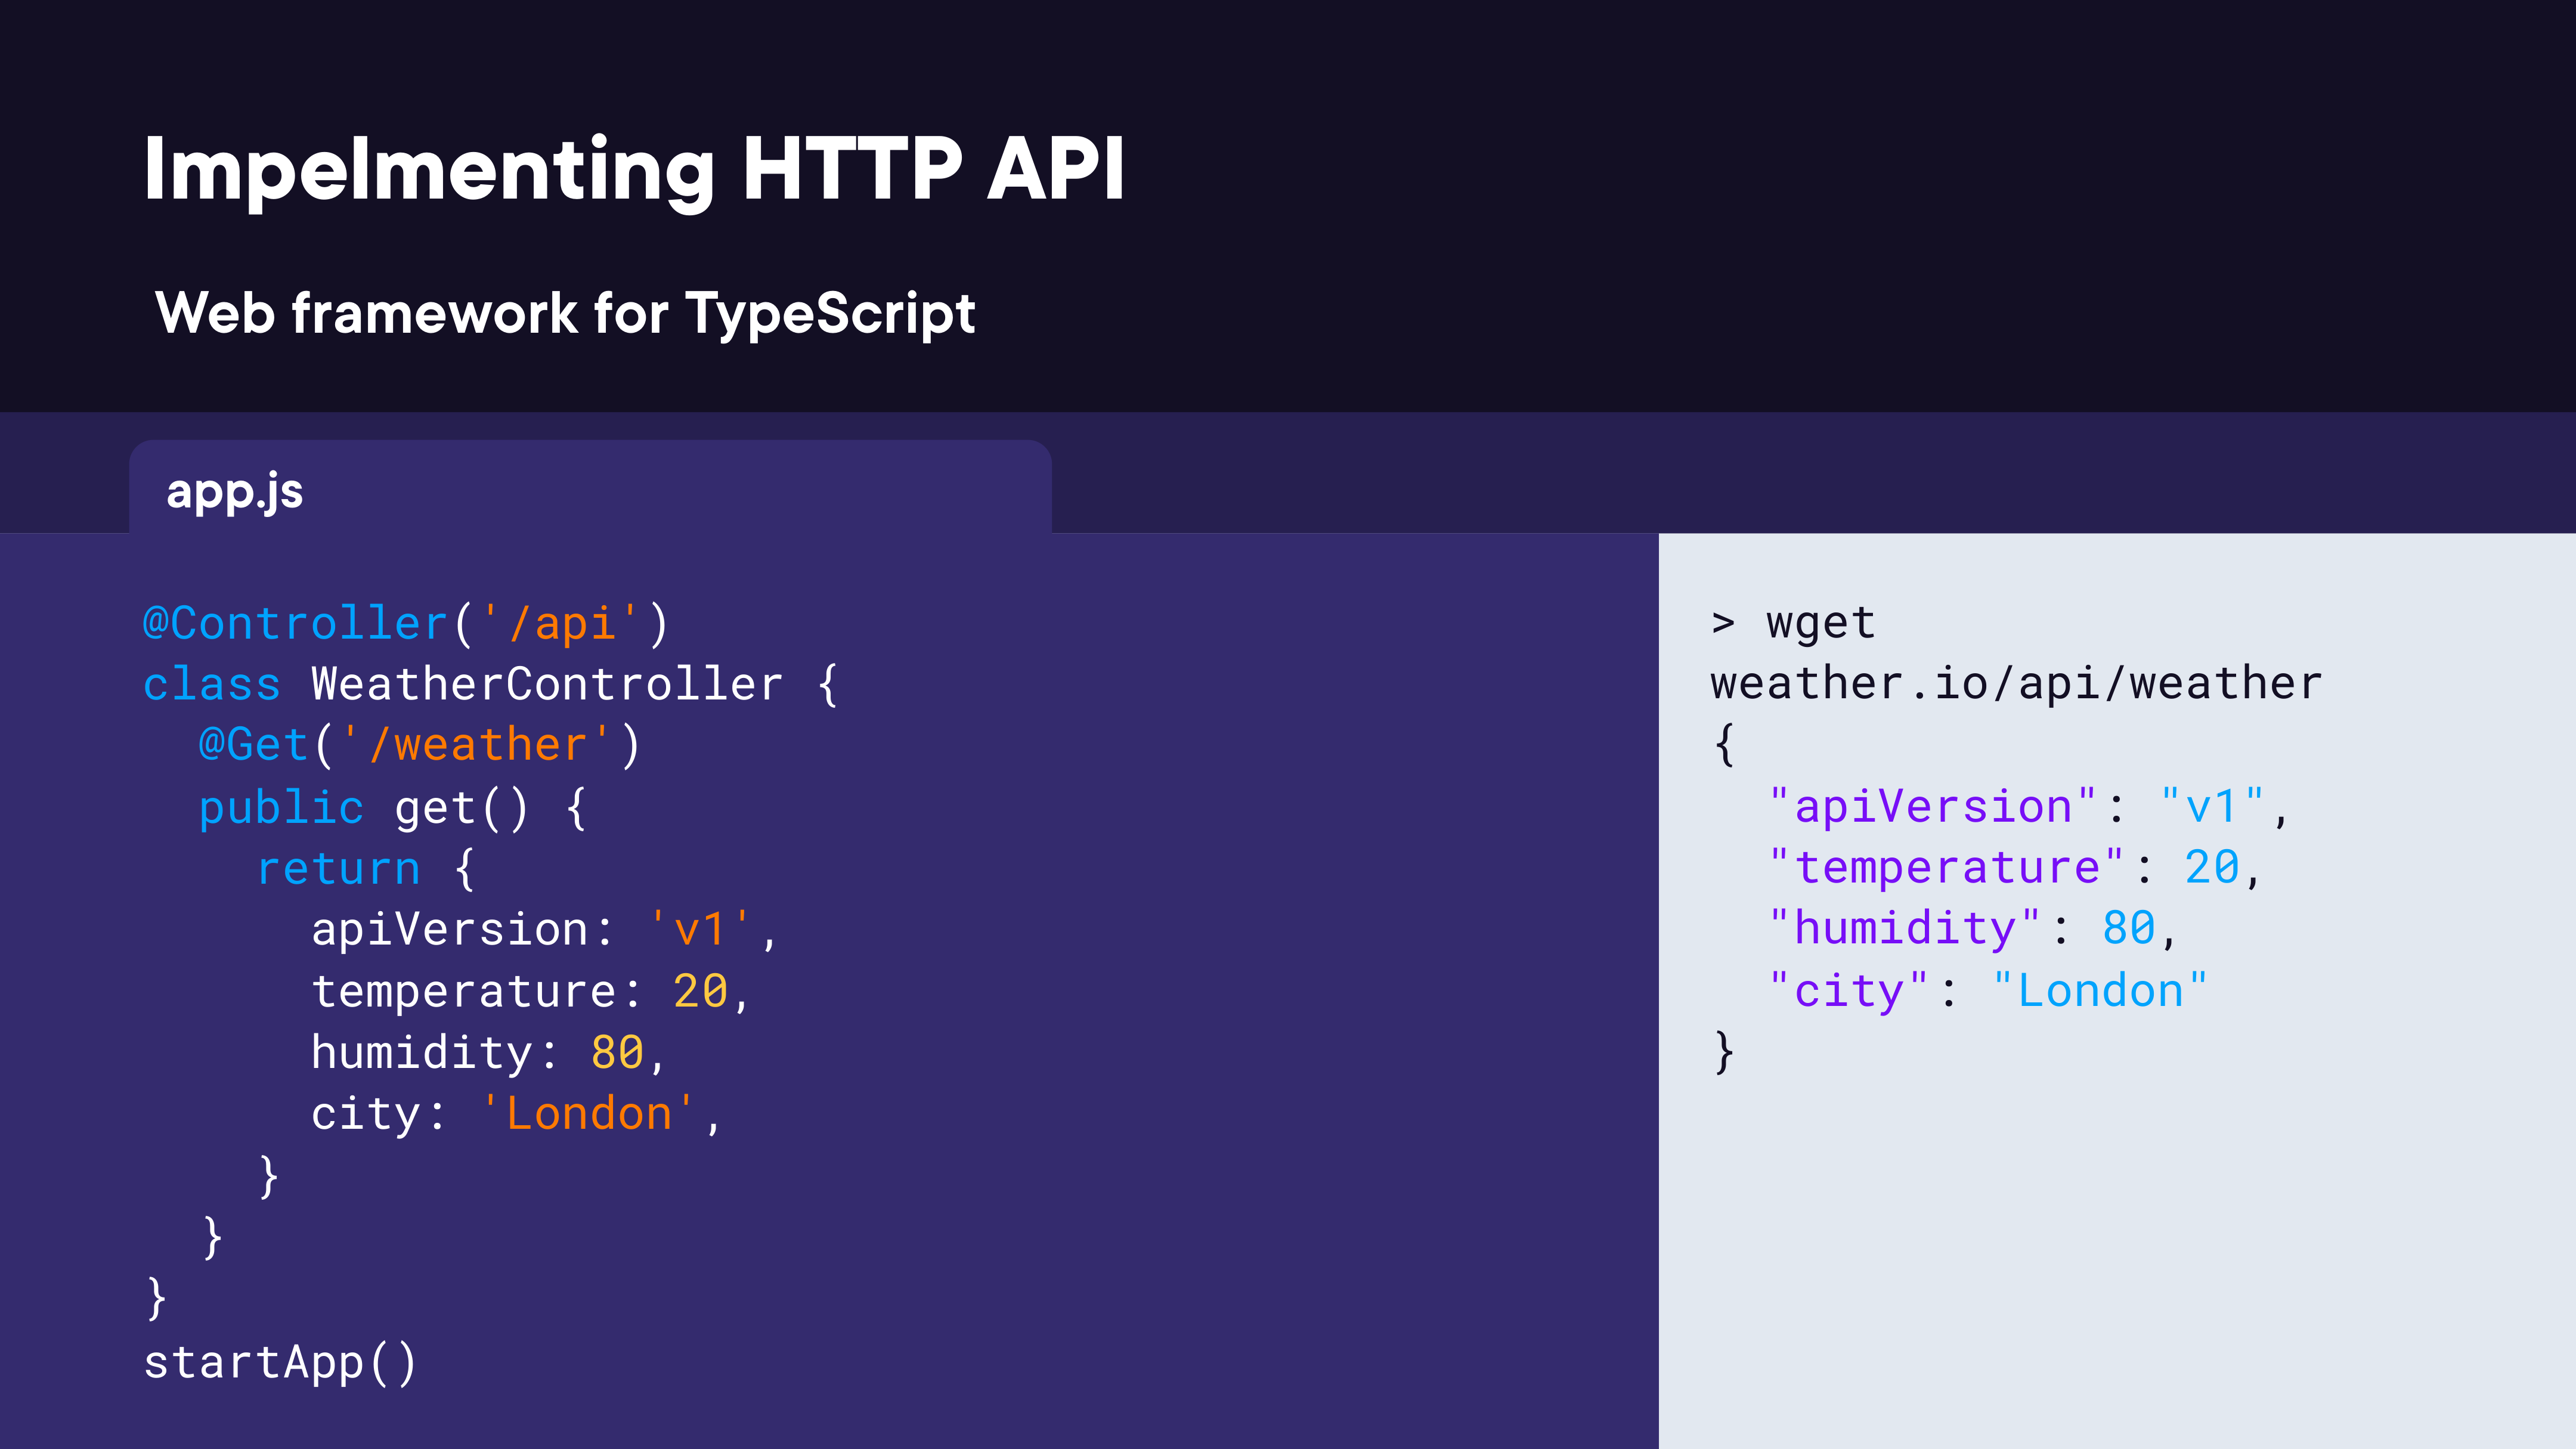

In [6]:
render_diagram(Path("assets/05-http-api-implementation.png"))

### Dependency Injection

**The problem:** wiring a complex object graph manually is tedious and makes testing difficult (replacing real components with test doubles requires touching all the construction code).

**The object graph:**


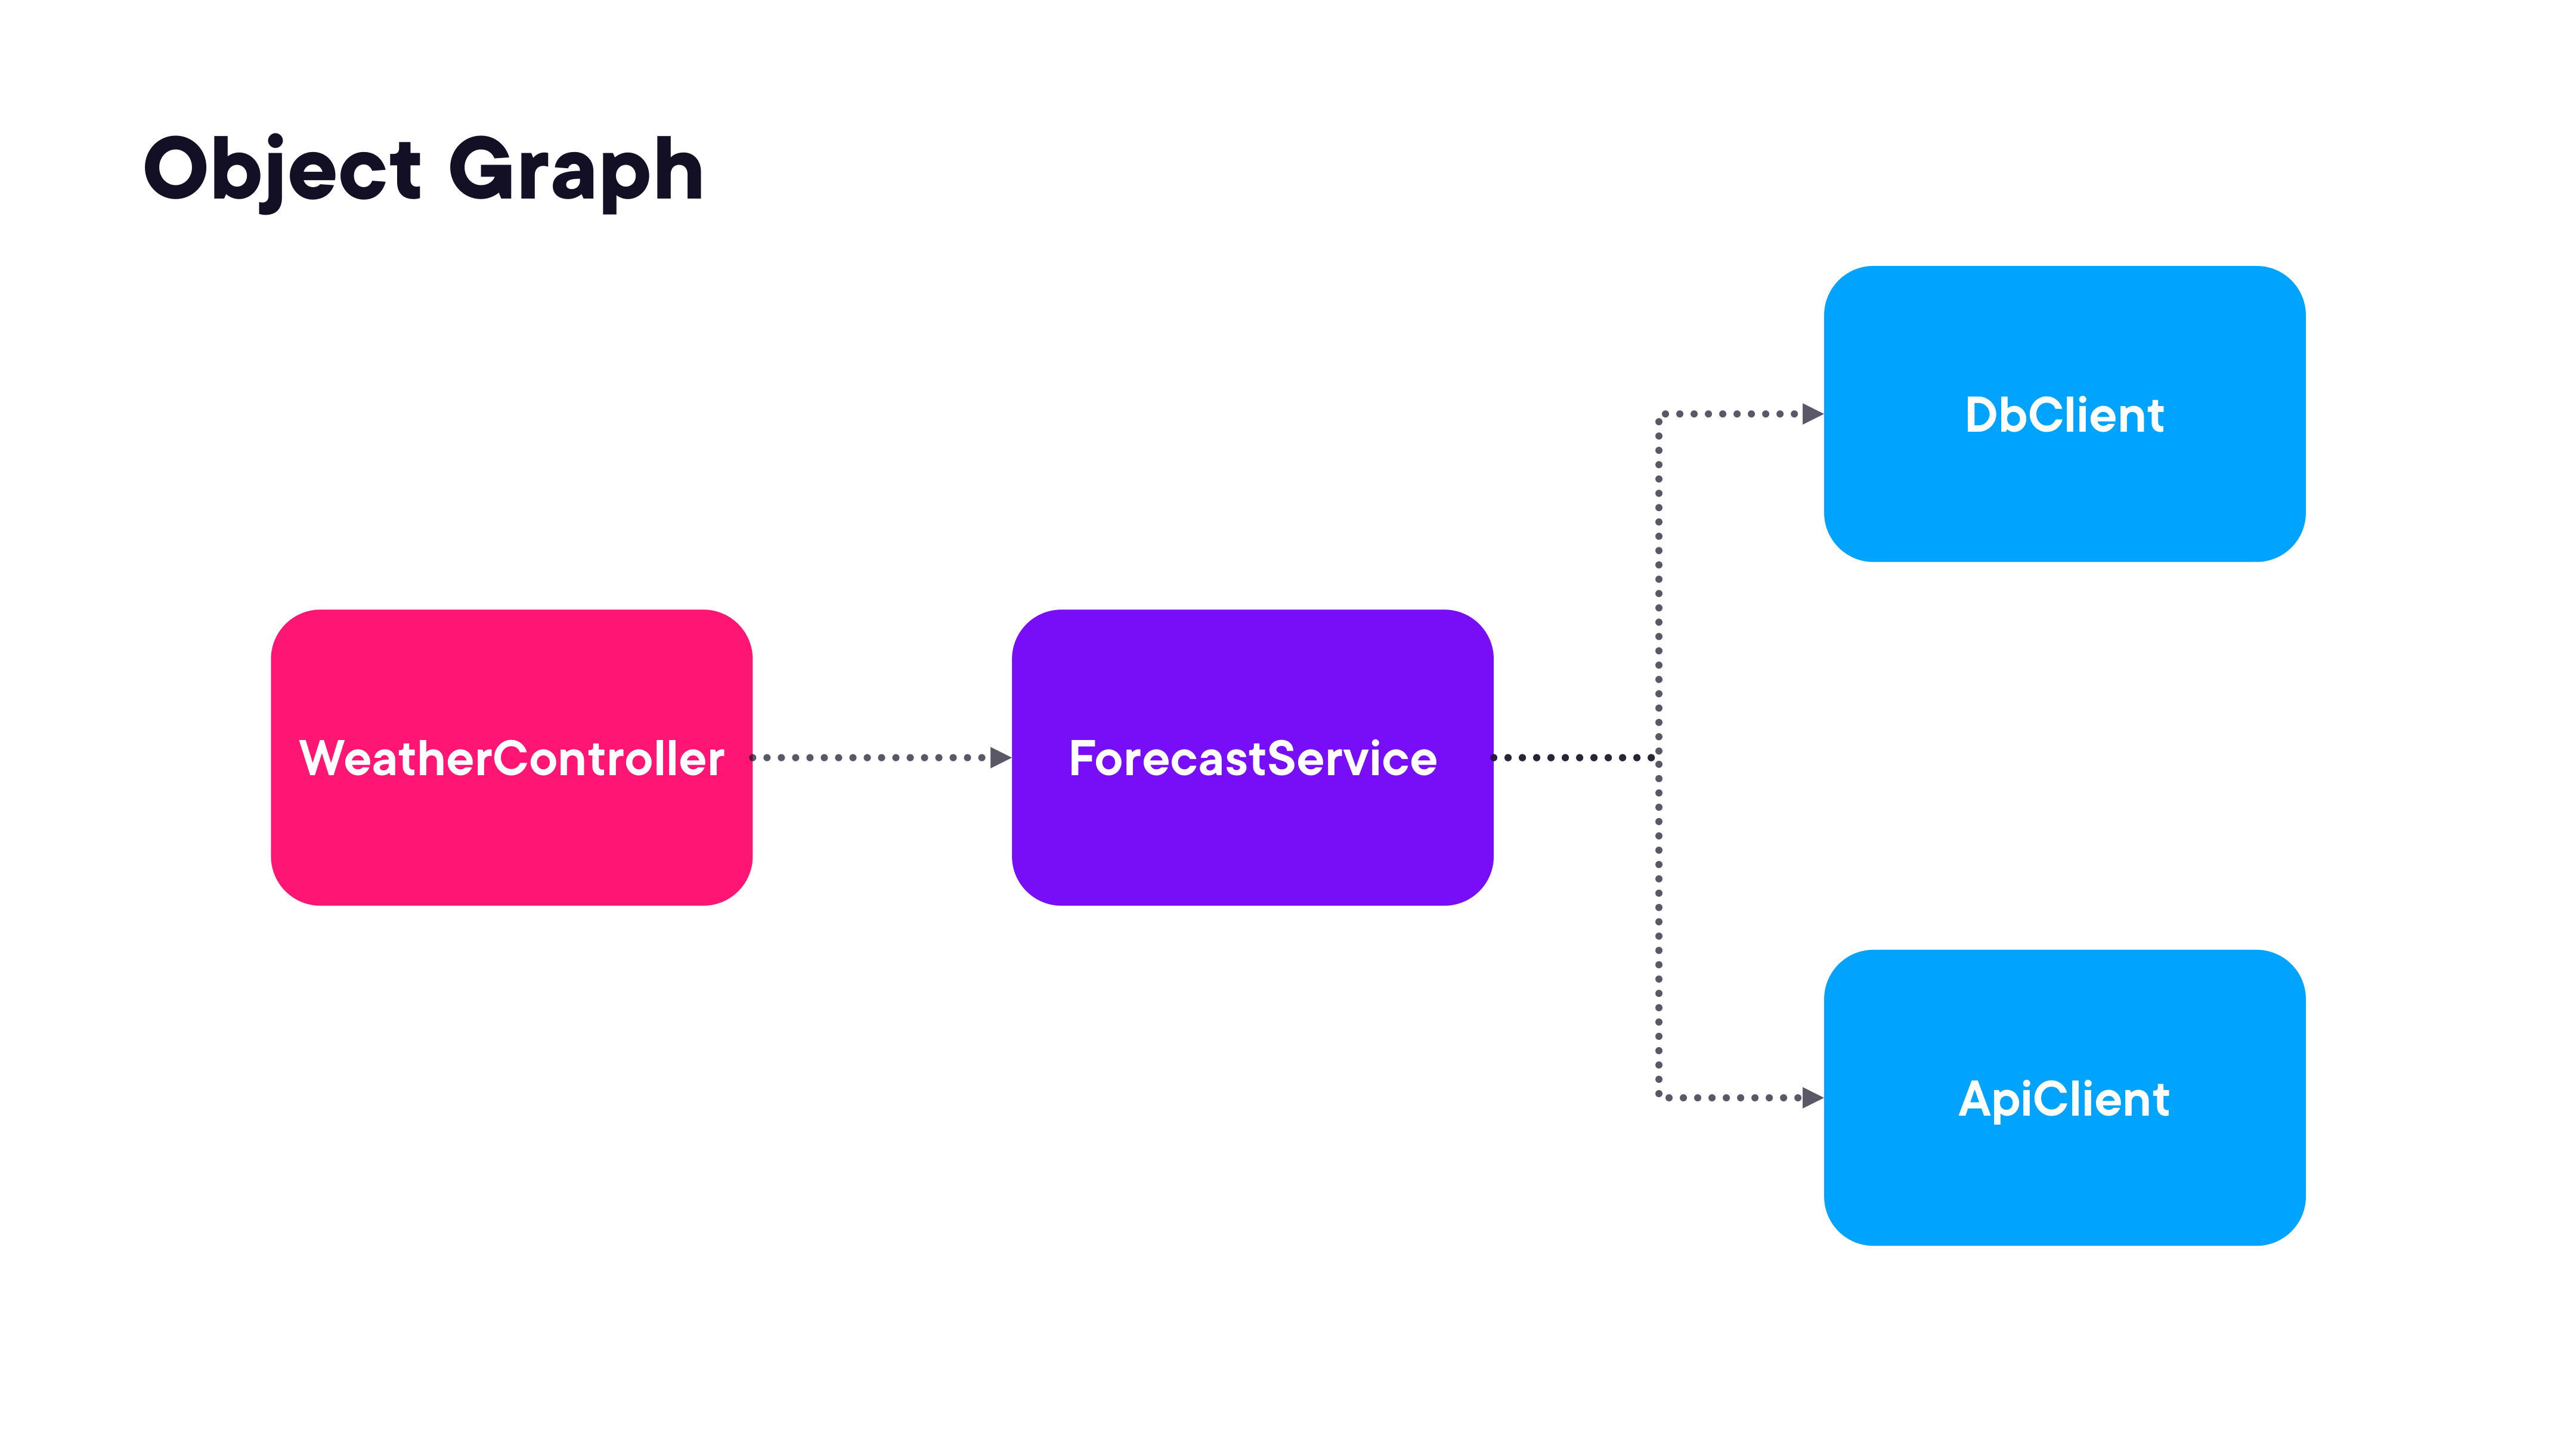

In [7]:
render_diagram(Path("assets/06-object-graph.png"))

Manual construction:

```javascript
const thirdPartyApiClient = new ThirdPartyApiClient(...);
const dbClient = new DbClient(...);
const forecastService = new ForecastService({
  dbClient: dbClient,
  thirdPartyApiClient: thirdPartyApiClient
});
const weatherController = new WeatherController({
  forecastService: forecastService
});
```

With decorator-based DI, the framework constructs this graph automatically:

```javascript
@Controller('/weather')
class WeatherController {
  @Inject('WeatherDataStorage')
  weatherStorage

  @Get('/forecast')
  public get() {
    return this.weatherStorage.getForecast()
  }
}

@Injectable('WeatherDataStorage')
class WeatherDataStorage {
  public getForecast() { return ... }
}
```

**For testing**, swap real dependencies with test doubles just by registering different `@Injectable` implementations — the controller code is unchanged.

Test doubles graph:


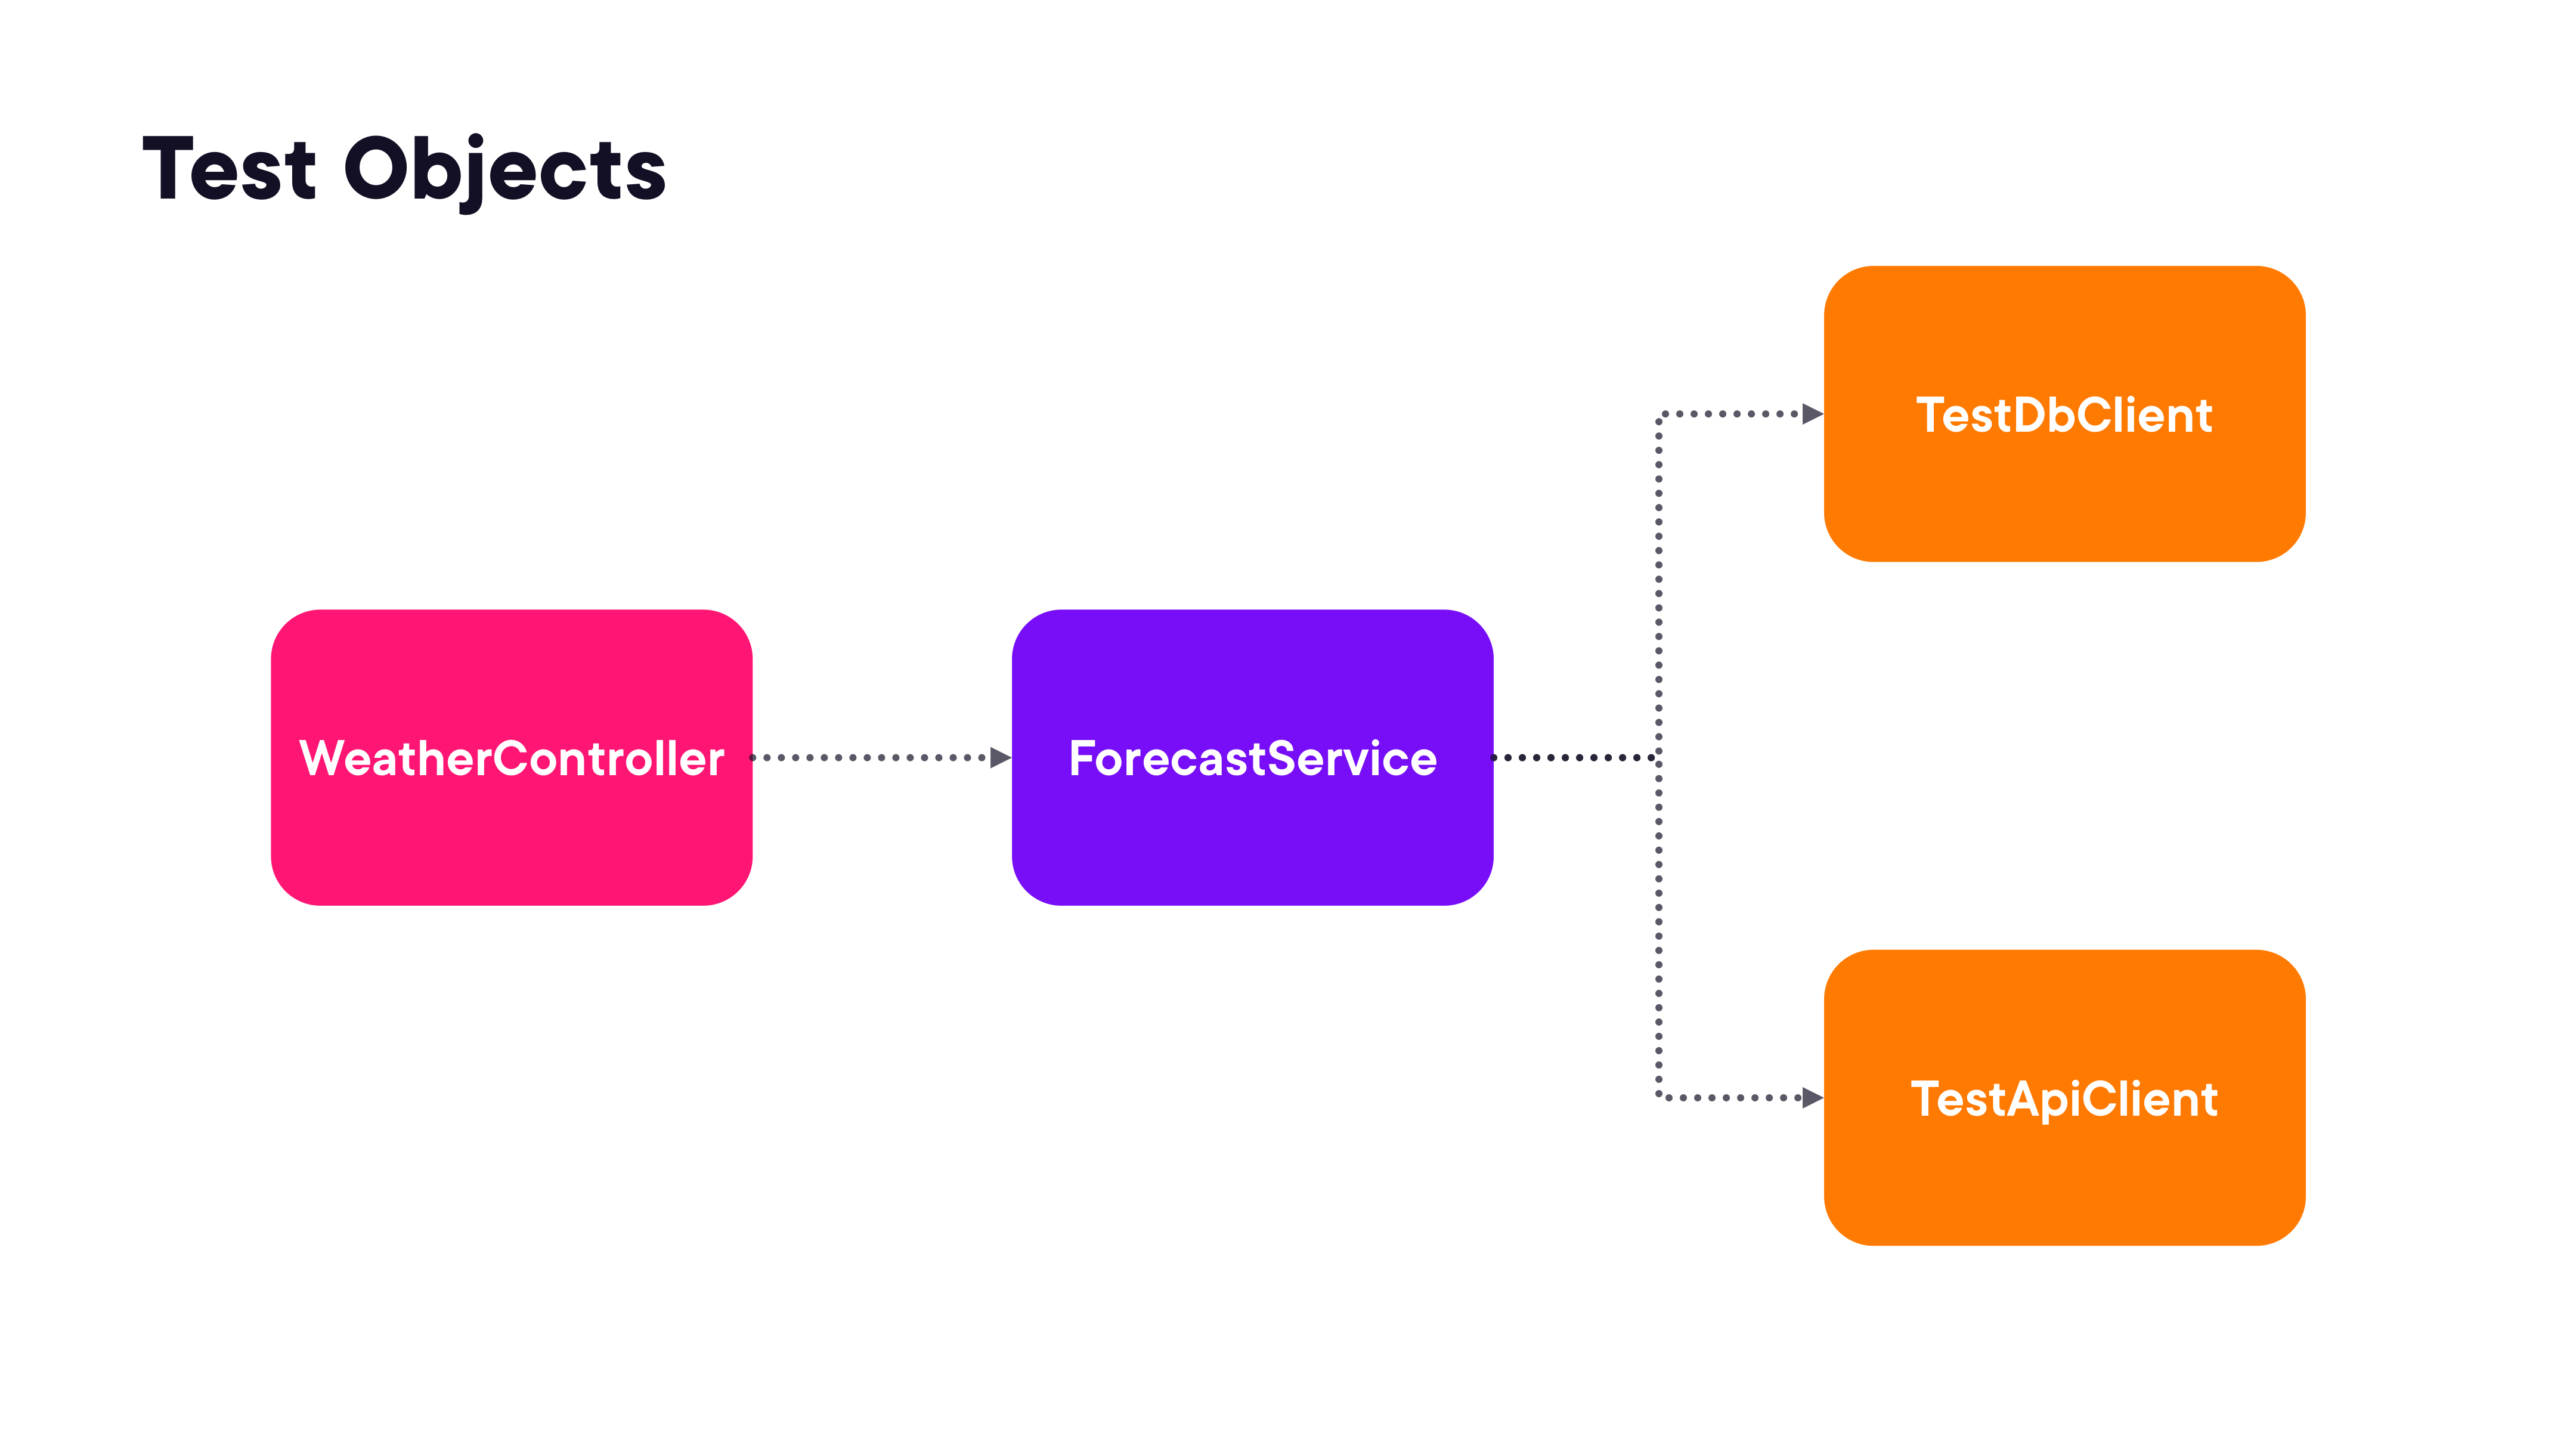

In [8]:
render_diagram(Path("assets/07-test-objects-graph.png"))

### Class Decorators

A class decorator is a function that receives the class constructor and optionally returns a new class. It can:
- Record the class in a registry
- Extend the class with new fields or behaviour
- Wrap the constructor to intercept new instances

```typescript
interface ClassDecoratorContext<Class> {
  readonly kind: "class"
  readonly name: string | undefined
  addInitializer(initializer: (this: Class) => void): void
  readonly metadata: DecoratorMetadata
}
```

#### Recording Decorated Classes

```javascript
const decoratedClasses = new Set()

function record(target, context) {
  decoratedClasses.add(target)
}

@record
class MyClass { ... }
```

#### Adding Fields

```javascript
function addNewField(target, context) {
  return class extends target {
    newField = 'newValue'
  }
}

@addNewField
class MyClass { ... }

const obj = new MyClass()
console.log(obj.newField)         // 'newValue'
console.log(obj instanceof MyClass) // true
```

#### Intercepting the Constructor

```javascript
function inspectConstructor(target, context) {
  return class extends target {
    constructor(...args) {
      super(...args)
      console.log(`Args: ${args}`)
    }
  }
}
```

#### Processing New Instances (e.g. freeze)

Returning a plain function (not a class) from a class decorator breaks `instanceof` unless you manually restore the prototype chain:

```javascript
function freeze(target, context) {
  const newConstructor = function (...args) {
    const instance = new target(...args)
    return Object.freeze(instance)
  }
  newConstructor.prototype = target.prototype  // restore instanceof
  return newConstructor
}

@freeze
class User {
  constructor(email) { this.email = email }
}

const user = new User('john@example.com')
user.email = 'other@example.com' // TypeError: Cannot assign to read only property
console.log(user instanceof User) // true
```

### Express.js Foundation

The web framework layer is built on top of **Express.js**, a popular Node.js HTTP framework:

```javascript
import express from 'express'

const app = express()

app.get('/user/current', (req, res) => {
  res.json({ userId: 12345, name: 'John Doe', email: 'johndoe@example.com' })
})

app.post('/user', (req, res) => {
  const { name, email } = req.body
  res.json({ status: 'success' })
})

app.get('/user/:userId', (req, res) => {
  const userId = req.params.userId
  res.json({ id: userId, ... })
})

app.listen(3000, () => console.log('Server running on port 3000'))
```

The decorator layer wraps Express — `@Get('/path')` registers an `app.get(...)` handler under the hood.

#### Implementing `@Controller` and `@Get`

```javascript
const pathForControllerCtor = new Map()

export function Controller(urlPath) {
  return function (target, context) {
    pathForControllerCtor.set(target, urlPath)
    return target
  }
}

export function Get(subPath) {
  return function (target, context) {
    context.addInitializer(function () {
      // 'this' is the controller instance
      const controllerPath = pathForControllerCtor.get(this.constructor)
      const fullPath = controllerPath + subPath
      app.get(fullPath, (req, res) => {
        const response = target.call(this)
        res.json(response)
      })
    })
    return target
  }
}
```

`addInitializer` runs *after* the class is fully defined and an instance is created — at that point `this.constructor` is available to look up the controller's registered path.

### Property Decorators

A property decorator receives `undefined` as `target` (unlike method decorators which receive the function) and returns an initializer function that replaces the field's initial value:

```typescript
type ClassPropertyDecorator = (
  target: undefined,
  context: {
    kind: 'field'
    name: string | symbol
    access: { get(): unknown; set(value: unknown): void }
    static: boolean
    private: boolean
  },
) => (initialValue: unknown) => unknown | void
```

```javascript
function notZero(target, context) {
  return function (initialValue) {
    if (initialValue === 0) {
      throw new Error('Initial value cannot be zero')
    }
    return initialValue
  }
}

class MyClass {
  @notZero
  myField = initValue()
}
```

The returned function runs once per instance creation, receiving the field's computed initial value and returning the value that will actually be stored.

### Accessor Decorators (Getters and Setters)

Decorators can be applied independently to `get` and `set` accessors:

```typescript
type ClassGetterDecorator = (
  value: Function,
  context: { kind: 'getter'; name: string | symbol; ... },
) => Function | void

type ClassSetterDecorator = (
  target: Function,
  context: { kind: 'setter'; name: string | symbol; ... },
) => Function | void
```

```javascript
class User {
  _email
  get email() { return this._email }
  set email(value) { this._email = value }
}
```

### Auto-Accessors

The `accessor` keyword is syntactic sugar that generates a getter, setter, and backing private field automatically:

```javascript
// Equivalent declarations:
class User { accessor email }

// Desugars to:
class User {
  #_email
  get email() { return this.#_email }
  set email(value) { this.#_email = value }
}
```

An auto-accessor decorator returns an object with optional `get`, `set`, and `init` overrides:

```typescript
type ClassAutoAccessorDecorator = (
  target: { get: () => unknown; set: (value: unknown) => void },
  context: {
    kind: 'accessor'
    name: string | symbol
    static: boolean
    private: boolean
    access: { get: () => unknown; set: (value: unknown) => void }
    addInitializer(initializer: () => void): void
  },
) => { get?: () => unknown; set?: (value: unknown) => void; init?: (initialValue: unknown) => unknown } | void
```

**Example — validate on set:**

```javascript
function notNegative(target, context) {
  return {
    set(newValue) {
      if (newValue < 0) {
        throw new Error('Value cannot be negative')
      }
      target.set.call(this, newValue)
    },
  }
}

class User {
  @notNegative
  accessor age
}

const user = new User()
user.age = -1  // Error: Value cannot be negative
```

### Decorator Metadata

The `context.metadata` object is shared across all decorators on a class — any decorator can write to it and the data is accessible after class creation via `ClassName[Symbol.metadata]`.

```javascript
function decorator(target, context) {
  context.metadata[context.name] = true
}

class User {
  @decorator name = 'John'
  @decorator age  = 42
}

console.log(User[Symbol.metadata]) // { name: true, age: true }
```

**Enable metadata support (Babel / polyfill required):**
```javascript
Symbol.metadata ??= Symbol('Symbol.metadata')
```

#### Validation Library Using Metadata

Metadata enables a clean, annotation-driven validation pattern — decorators accumulate constraint checks; a `validate()` function runs them all:

```javascript
function required(target, context) {
  const required = (context.metadata['requiredKeys'] ??= [])
  required.push(context.name)
}

function validate(object) {
  const metadata = object.constructor[Symbol.metadata]
  const requiredFields = metadata['requiredKeys']
  for (const field of requiredFields) {
    if (object[field] === undefined || object[field] === null) {
      throw new Error(`${field} is required`)
    }
  }
}

class User {
  @required username
  @required email
  location            // not required
}
```

### Decorator Limitations and Future Proposals

Two useful features that are **not yet part of the standard**:

#### Parameter Decorators (Stage 1)

Decorate individual method parameters to extract HTTP request data (query params, path params, body):

```javascript
// Hypothetical future syntax
@Controller('')
class WeatherController {
  @Get('/api')
  public get(
    @QueryParameter('cityName') city: string
  ) {
    return weatherClient.fetchWeather(city)
  }
}
```

Currently at Stage 1 — not supported by TypeScript 5+ (was supported in pre-5.0 experimental decorators).

#### Function Expression Decorators — Not Supported

Applying decorators to non-class function expressions is not part of the current proposal:

```javascript
// Not valid syntax:
scheduleTask(@retry function() { ... })
```

The current standard only supports decorators on class elements (methods, fields, accessors) and classes themselves.

### Demo: Decorator-Based Web Framework

This demo implements the full framework: `@Controller`, `@Get`, `@Injectable`, `@Inject`, and a metadata-driven validation library (`@notNull`, `@notNegative`, `validateObject`), all built on top of Express.js.

See [`03-decorator-based-web-framework-demos/`](03-decorator-based-web-framework-demos/) for the full project.

Key files:
- **`src/framework.js`** — the framework implementation (Controller, Get, Injectable, Inject, validateObject)
- **`src/app.js`** — application code using the framework (CitiesDB, WeatherController, CitiesController)
- **`src/test-validation.js`** — demonstrates the metadata-based validation library

```javascript
// app.js — using the complete framework
@Injectable('CitiesDB')
class CitiesDB {
  getCities() {
    return ['London', 'New York', 'Dublin']
  }
}

@Controller('/api')
class CitiesController {
  @Inject('CitiesDB')
  citiesDb

  @Get('/cities')
  get() {
    return { cities: this.citiesDb.getCities() }
  }
}

startApp()
```

```javascript
// test-validation.js — metadata-based validation
Symbol.metadata ??= Symbol('Symbol.metadata')

class User {
  @notNull   username
  @notNegative age
  @notNull   location
}

const user = new User()
user.username = 'John'
user.age = -1
user.location = null

console.log(validateObject(user))
// { errors: ["'age' must be non-negative", "'location' is required"], isValid: false }
```